# Lecture 23

# A Few More OOP methods and Some Pythonic Features

## Week 9 Monday

## Miles Chen, PhD

## The `Card` class so far

The `Card` class has an `__init__` method which assigns a numeric value to the suit and to the rank.

It has a few methods: 

- `__str__` which is used to show the card in a user-friendly form.
- `__lt__` which is used for comparison and allows card objects to be sorted
- `__eq__` which is used to test equality

In [1]:
class Card:
    def __init__(self, suit = 0, rank = 2):
        self.suit = suit
        self.rank = rank
    
    suit_names = ['Clubs', 'Diamonds', 'Hearts', 'Spades']
    rank_names = [None, 'Ace', '2', '3', '4', '5', '6', '7',
                 '8', '9', '10', 'Jack', 'Queen', 'King']
    
    def __str__(self):
        return "{:s} of {:s}".format(Card.rank_names[self.rank],
                             Card.suit_names[self.suit])
    
    def __lt__(self, other):
        t1 = self.suit, self.rank
        t2 = other.suit, other.rank
        return t1 < t2
    
    def __eq__(self, other):
        t1 = self.suit, self.rank
        t2 = other.suit, other.rank
        return t1 == t2

## The Deck class so far

The `Deck` class has a few methods: 

- `__init__` method which creates 52 cards and stores them in a list `self.cards`
- `__str__` which iterates through all items in the `self.cards` list and prints them
- `pop_card` which pops the last card in the list `self.cards`
- `add_card` which appends a card in the list `self.cards`
- `shuffle` which shuffles the list `self.cards`
- `sort` which sorts the list `self.cards`. It is able to do this because the `Card` objects have `__lt__` which allows for comparison
- `move_cards` which moves cards from the deck to a hand.

Note: `shuffle` requires us to import the `random` module into Python


In [2]:
import random
random.seed(10)

In [3]:
class Deck:
    def __init__(self):
        self.cards = []
        for suit in range(4):
            for rank in range(1,14):
                card = Card(suit, rank)
                self.cards.append(card)
    def __str__(self):
        res = []
        for card in self.cards:
            res.append(str(card))
        return '\n'.join(res)
    
    def pop_card(self):
        return self.cards.pop()
    
    def add_card(self, card):
        self.cards.append(card)
    
    def shuffle(self):
        random.shuffle(self.cards)
    
    def sort(self):
        self.cards.sort()
        
    def move_cards(self, hand, num):
        for i in range(num):
            hand.add_card(self.pop_card())

## The Hand class so far

The `Hand` class inherits from the `Deck` class, so it learns all of the same methods.

We change the `__init__` method so the hand starts off empty. We also provide the hand a label.

In [4]:
class Hand(Deck):
    def __init__(self, label = ""):
        self.cards = []
        self.label = label

In [5]:
deck = Deck()
hand = Hand('new hand')

In [6]:
deck.move_cards(hand, 5)

In [7]:
print(hand)

King of Spades
Queen of Spades
Jack of Spades
10 of Spades
9 of Spades


## Current limitation

Even though we have a string representation of the card, when we create a card, the object itself is represented as an object in memory.

In [8]:
card1 = Card()
card2 = Card(3, 11)

In [9]:
card1

In [10]:
print(card1)

2 of Clubs


In [11]:
card2

In [12]:
print(card2)

Jack of Spades


This is even worse when looking at a deck or hand object

In [13]:
hand = Hand('new hand')
deck.move_cards(hand, 5)
hand.cards

As it stands, this is completely unintelligible

## The `__repr__` method

The dunder (double-underscore) method `__repr__` is used to show the 'official' representation of the card object. The output should be the command that is able to create this card object.

When we created the Jack of Spades and set it equal, we called

`card2 = Card(3, 11)`

Thus, `Card(3, 11)` would be the official representation of this object.

In [14]:
class Card:
    def __init__(self, suit = 0, rank = 2):
        self.suit = suit
        self.rank = rank
    
    suit_names = ['Clubs', 'Diamonds', 'Hearts', 'Spades']
    rank_names = [None, 'Ace', '2', '3', '4', '5', '6', '7',
                 '8', '9', '10', 'Jack', 'Queen', 'King']
    
    def __str__(self):
        return "{:s} of {:s}".format(Card.rank_names[self.rank],
                             Card.suit_names[self.suit])
    
    def __repr__(self):
        return "Card({}, {})".format(self.suit, self.rank)
    
    def __lt__(self, other):
        t1 = self.suit, self.rank
        t2 = other.suit, other.rank
        return t1 < t2
    
    def __eq__(self, other):
        t1 = self.suit, self.rank
        t2 = other.suit, other.rank
        return t1 == t2

In [15]:
# card2 was created under the old Card definition and does not have the __repr__ method
card2

In [16]:
print(card2)

Jack of Spades


In [17]:
card3 = Card(3, 11) # We create another Jack of Spades using the new Card class with the repr method

In [18]:
card3

Card(3, 11)

In [19]:
print(card3)

Jack of Spades


In [20]:
card3 == card2

True

In [21]:
# Note: Deck.__init__ looks up Card dynamically, so calling Deck() already uses the new Card.
# We re-run class Deck here just to keep the full definition together.
class Deck:
    def __init__(self):
        self.cards = []
        for suit in range(4):
            for rank in range(1,14):
                card = Card(suit, rank)
                self.cards.append(card)
    def __str__(self):
        res = []
        for card in self.cards:
            res.append(str(card))
        return '\n'.join(res)
    
    def pop_card(self):
        return self.cards.pop()
    
    def add_card(self, card):
        self.cards.append(card)
    
    def shuffle(self):
        random.shuffle(self.cards)
    
    def sort(self):
        self.cards.sort()
        
    def move_cards(self, hand, num):
        for i in range(num):
            hand.add_card(self.pop_card())

In [22]:
class Hand(Deck):
    def __init__(self, label = ""):
        self.cards = []
        self.label = label

In [23]:
deck = Deck()
hand = Hand('new hand')
deck.move_cards(hand, 5)

In [24]:
print(hand)

King of Spades
Queen of Spades
Jack of Spades
10 of Spades
9 of Spades


In [25]:
hand.cards # although not as easy to read as the string representation, the representation makes more sense.

[Card(3, 13), Card(3, 12), Card(3, 11), Card(3, 10), Card(3, 9)]

## How many cards are in the deck or hand?

Right now, if we want to know how many cards are in the deck or hand, we have to access the list of cards in the hand or deck directly.

In [26]:
hand

In [27]:
len(hand)

TypeError: object of type 'Hand' has no len()

In [28]:
vars(hand)

{'cards': [Card(3, 13), Card(3, 12), Card(3, 11), Card(3, 10), Card(3, 9)],
 'label': 'new hand'}

In [29]:
len(hand.cards)

5

## Defining the length of a class

We can fix this issue by defining the `__len__` special method, which will return the length of `self.cards`

```
    def __len__(self):
        return len(self.cards)
```        

In [30]:
class Deck:
    def __init__(self):
        self.cards = []
        for suit in range(4):
            for rank in range(1,14):
                card = Card(suit, rank)
                self.cards.append(card)
    def __str__(self):
        res = []
        for card in self.cards:
            res.append(str(card))
        return '\n'.join(res)
    
    def __len__(self):
        return len(self.cards)
    
    def pop_card(self):
        return self.cards.pop()
    
    def add_card(self, card):
        self.cards.append(card)
    
    def shuffle(self):
        random.shuffle(self.cards)
    
    def sort(self):
        self.cards.sort()
        
    def move_cards(self, hand, num):
        for i in range(num):
            hand.add_card(self.pop_card())

In [31]:
class Hand(Deck):
    def __init__(self, label = ""):
        self.cards = []
        self.label = label

In [32]:
deck = Deck()
len(deck)

52

In [33]:
hand = Hand('new hand')
deck.move_cards(hand, 5)

In [34]:
len(hand)

5

In [35]:
len(deck)

47

## What if we wanted to access the first 5 cards from the deck?


In [36]:
deck[0:5]

TypeError: 'Deck' object is not subscriptable

Right now, our deck cannot be sliced.

In [37]:
deck[0]

TypeError: 'Deck' object is not subscriptable

## What if we want to iterate through the deck?

In [38]:
for card in deck:
    print(card)

TypeError: 'Deck' object is not iterable

Right now, our deck is not iterable.

## What if we want to see the hand sorted without changing the hand?

In [39]:
sorted(hand)

TypeError: 'Hand' object is not iterable

This is not possible right now.

# Making the class behave like a list or container:

https://docs.python.org/3/reference/datamodel.html#emulating-container-types

We can take the class and allow the user to slice the object as well as perform iteration.

This is achieved with the dunder method: `__getitem__(self, key)` which tells Python what to do when a particular position is requested from the class object.

In our case, we will use the `key` as an index `position`. We return the card located in the requested `[position]` from the `self.cards` list.

```
    def __getitem__(self, position):
        return self.cards[position]
```

Bonus: when `__iter__` is not defined, Python falls back to calling `__getitem__(0)`, `__getitem__(1)`, ... until `IndexError`, which is why `for card in deck:`, `sorted(hand)`, and tuple unpacking all start working! Also notice that slicing `deck[0:8]` returns a plain `list` of `Card` objects because `self.cards[position]` delegates to the underlying `list`.

In [40]:
class Deck:
    def __init__(self):
        self.cards = []
        for suit in range(4):
            for rank in range(1,14):
                card = Card(suit, rank)
                self.cards.append(card)
    def __str__(self):
        res = []
        for card in self.cards:
            res.append(str(card))
        return '\n'.join(res)
    
    def __len__(self):
        return len(self.cards)
    
    def __getitem__(self, position):
        return self.cards[position]
    
    def pop_card(self):
        return self.cards.pop()
    
    def add_card(self, card):
        self.cards.append(card)
    
    def shuffle(self):
        random.shuffle(self.cards)
    
    def sort(self):
        self.cards.sort()
        
    def move_cards(self, hand, num):
        for i in range(num):
            hand.add_card(self.pop_card())

In [41]:
deck = Deck()
print(deck)

Ace of Clubs
2 of Clubs
3 of Clubs
4 of Clubs
5 of Clubs
6 of Clubs
7 of Clubs
8 of Clubs
9 of Clubs
10 of Clubs
Jack of Clubs
Queen of Clubs
King of Clubs
Ace of Diamonds
2 of Diamonds
3 of Diamonds
4 of Diamonds
5 of Diamonds
6 of Diamonds
7 of Diamonds
8 of Diamonds
9 of Diamonds
10 of Diamonds
Jack of Diamonds
Queen of Diamonds
King of Diamonds
Ace of Hearts
2 of Hearts
3 of Hearts
4 of Hearts
5 of Hearts
6 of Hearts
7 of Hearts
8 of Hearts
9 of Hearts
10 of Hearts
Jack of Hearts
Queen of Hearts
King of Hearts
Ace of Spades
2 of Spades
3 of Spades
4 of Spades
5 of Spades
6 of Spades
7 of Spades
8 of Spades
9 of Spades
10 of Spades
Jack of Spades
Queen of Spades
King of Spades


In [42]:
# We can now perform slicing
deck[0:8]

[Card(0, 1),
 Card(0, 2),
 Card(0, 3),
 Card(0, 4),
 Card(0, 5),
 Card(0, 6),
 Card(0, 7),
 Card(0, 8)]

In [43]:
# We can also perform iteration
for item in deck[0:8]:
    print(item)

Ace of Clubs
2 of Clubs
3 of Clubs
4 of Clubs
5 of Clubs
6 of Clubs
7 of Clubs
8 of Clubs


With `__getitem__` implemented, all of the slicing rules now work with our Class:

In [44]:
# I select the index-12th card, the King of clubs and get every 13th card after:
deck[12::13]

[Card(0, 13), Card(1, 13), Card(2, 13), Card(3, 13)]

In [45]:
for item in deck[12::13]:
    print(item)

King of Clubs
King of Diamonds
King of Hearts
King of Spades


In [46]:
class Hand(Deck):
    def __init__(self, label = ""):
        self.cards = []
        self.label = label

In [47]:
deck = Deck()
deck.shuffle()
hand = Hand('new hand')
deck.move_cards(hand, 5)

In [48]:
# sorted arranges by suit
for card in sorted(hand):
    print(card)

3 of Clubs
2 of Hearts
5 of Hearts
Jack of Hearts
King of Spades


In [49]:
print(hand) # original hand is left unchanged

Jack of Hearts
3 of Clubs
2 of Hearts
5 of Hearts
King of Spades


In [50]:
a,b,c,d,e = hand # now that we have __getitem__, we can also perform tuple unpacking

In [51]:
a

Card(2, 11)

In [52]:
print(b)

3 of Clubs


In [53]:
hand

In [54]:
print(hand)

Jack of Hearts
3 of Clubs
2 of Hearts
5 of Hearts
King of Spades


In [55]:
hand[0]

Card(2, 11)

In [56]:
hand[0] = Card(2,1)

TypeError: 'Hand' object does not support item assignment

## set item

The `__setitem__` method allows you to set items in the Class.

In our case, we can use it to assign a particular Card object to a particular position in the list of cards. 

```
    def __setitem__(self, key, value):
        self.cards[key] = value
```

Functions like `random.shuffle()` use `__len__`, `__getitem__`, and `__setitem__` together to rearrange objects inside a container.

With `__setitem__` implemented, we can get rid of the internal `deck.shuffle()` method and simply use the `random.shuffle()` function.

In [57]:
class Deck:
    def __init__(self):
        self.cards = []
        for suit in range(4):
            for rank in range(1,14):
                card = Card(suit, rank)
                self.cards.append(card)
    def __str__(self):
        res = []
        for card in self.cards:
            res.append(str(card))
        return '\n'.join(res)
    
    def __len__(self):
        return len(self.cards)
    
    def __getitem__(self, position):
        return self.cards[position]
    
    def __setitem__(self, key, value):
        self.cards[key] = value
    
    def pop_card(self):
        return self.cards.pop()
    
    def add_card(self, card):
        self.cards.append(card)
    
    # no longer needed:
    # def shuffle(self):
    #     random.shuffle(self.cards)
    
    def sort(self):
        self.cards.sort()
        
    def move_cards(self, hand, num):
        for i in range(num):
            hand.add_card(self.pop_card())

In [58]:
deck = Deck()

In [59]:
for card in deck[0:4]:
    print(card)

Ace of Clubs
2 of Clubs
3 of Clubs
4 of Clubs


In [60]:
deck[0]

Card(0, 1)

In [61]:
deck[0] = Card(3, 1) # with __setitem__ in place, you can replace items (swapping Ace of Clubs for a second Ace of Spades)

In [62]:
for card in deck[0:4]:
    print(card)

Ace of Spades
2 of Clubs
3 of Clubs
4 of Clubs


In [63]:
random.shuffle(deck) # We can call random.shuffle() directly on deck instead of calling deck.shuffle()

In [64]:
for card in deck[0:10]:
    print(card)

9 of Diamonds
5 of Spades
Ace of Spades
King of Hearts
4 of Diamonds
10 of Spades
Jack of Diamonds
5 of Diamonds
2 of Clubs
9 of Spades


In [65]:
for i in sorted(deck):
    print(i)

2 of Clubs
3 of Clubs
4 of Clubs
5 of Clubs
6 of Clubs
7 of Clubs
8 of Clubs
9 of Clubs
10 of Clubs
Jack of Clubs
Queen of Clubs
King of Clubs
Ace of Diamonds
2 of Diamonds
3 of Diamonds
4 of Diamonds
5 of Diamonds
6 of Diamonds
7 of Diamonds
8 of Diamonds
9 of Diamonds
10 of Diamonds
Jack of Diamonds
Queen of Diamonds
King of Diamonds
Ace of Hearts
2 of Hearts
3 of Hearts
4 of Hearts
5 of Hearts
6 of Hearts
7 of Hearts
8 of Hearts
9 of Hearts
10 of Hearts
Jack of Hearts
Queen of Hearts
King of Hearts
Ace of Spades
Ace of Spades
2 of Spades
3 of Spades
4 of Spades
5 of Spades
6 of Spades
7 of Spades
8 of Spades
9 of Spades
10 of Spades
Jack of Spades
Queen of Spades
King of Spades


## "Private" Attributes in Classes

Remember `Point` from Lecture 20, where nothing stopped someone from setting `blank.x = "dog"`? Let's revisit a 2D point/vector class (`Vector2d`, adapted from *Fluent Python* by Luciano Ramalho) and see how we can protect its attributes.

First, here's a straightforward version without attribute protection:

In [66]:
class Vector2d:
    def __init__(self, x, y):
        self.x = float(x)
        self.y = float(y)

    def __iter__(self): # generator expression yielding x, then y (makes the object iterable/unpackable)
        return (i for i in (self.x, self.y))

    def __repr__(self):
        class_name = type(self).__name__
        return '{}({}, {})'.format(class_name, *self) # *self unpacks x and y

    def __str__(self):
        return str(tuple(self))

In [67]:
myvector = Vector2d(3,4)

In [68]:
myvector

Vector2d(3.0, 4.0)

In [69]:
str(myvector)

'(3.0, 4.0)'

However, anyone can change the values

In [70]:
myvector.x = "dog"

In [71]:
myvector

Vector2d(dog, 4.0)

We can address this with two tools working together:

1. Preceding an attribute name with two underscores (`self.__x`) triggers **name mangling** so it can't be accessed directly as `.__x`.
2. Defining methods `x` and `y` with the `@property` decorator creates **read-only properties**—trying to assign `myvector.x = "dog"` will fail because there is no setter.

More information: https://www.freecodecamp.org/news/python-property-decorator/

In [72]:
class Vector2d:
    def __init__(self, x, y):
        self.__x = float(x)   
        self.__y = float(y)
        
    @property   
    def x(self):   
        return self.__x   
        
    @property   
    def y(self):
        return self.__y
        
    def __iter__(self):
        return (i for i in (self.x, self.y))
    def __repr__(self):
        class_name = type(self).__name__
        return '{}({}, {})'.format(class_name, *self)   
    def __str__(self):
        return str(tuple(self)) 

In [73]:
myvector = Vector2d(3,4)

In [74]:
myvector.x

3.0

In [75]:
myvector.x = "dog" # no longer works

AttributeError: property 'x' of 'Vector2d' object has no setter

In [76]:
myvector.__x # cannot access value directly

AttributeError: 'Vector2d' object has no attribute '__x'

'private' values in python aren't truly private because 
there is still a hidden way to access the value directly, 
but this is discouraged and violates "pythonic" principles.
The form to get the private attribute is:
`object._classname__privateAttribute`

In [77]:
myvector._Vector2d__x # 'secret' way to directly access and even modify the value

3.0

What if we *do* want to allow updating `x`, as long as the new value is a valid number? We can pair `@property` with a `@x.setter` method that validates or converts the input:

In [78]:
class Vector2d:
    def __init__(self, x, y):
        self.x = x   # calls the x.setter below!
        self.__y = float(y)

    @property
    def x(self):
        return self.__x

    @x.setter
    def x(self, value):
        self.__x = float(value)

    @property
    def y(self):
        return self.__y

    def __repr__(self):
        return f'Vector2d({self.x}, {self.y})'

v = Vector2d(3, 4)
v.x = 10
v

Vector2d(10.0, 4.0)

In [79]:
v.x = "dog" # now raises ValueError because float("dog") fails

ValueError: could not convert string to float: 'dog'

# Pythonic Features

Switching gears from OOP methods, let's wrap up with a few concise, "Pythonic" language features taken from Chapter 19 of Think Python by Allen B Downey.

Python has a number of features that are not necessary, but with them you can sometimes write code that's more concise, readable, or efficient.

## Conditional Expressions

A conditional expression will check a condition and run the associated code.

The following example shows how we can ask Python to find the natural log of a number. real-valued logarithms are not defined for non-positive values, so if x is less than or equal to zero, we want to return `nan` instead of an error.

In [80]:
x = -3

In [81]:
import math

In [82]:
if x > 0:
    y = math.log(x)
else:
    y = float('nan')
y

nan

We can express the same idea more concisely with a conditional expression.

In [83]:
x = math.e

In [84]:
y = math.log(x) if x > 0 else float('nan')

In [85]:
y

1.0

In [86]:
x = -5
y = math.log(x) if x > 0 else float('nan')
y

nan

Recursive functions can be rewritten as conditional expressions.

In [87]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return n * factorial(n-1)

In [88]:
factorial(5)

120

In [89]:
def factorial(n):
    return 1 if n == 0 else n * factorial(n - 1)

In [90]:
factorial(6)

720

The conditional expression is certainly more concise. Whether it is more readable is debatable.

In general, if both branches of a conditional statement are simple expressions that are assigned or a returned, it can be written as a conditional expression.

## Variable Length Arguments and Key-Word Arguments

When we covered tuples, we saw that you can gather arguments together with `*`

In [91]:
def print_all(*args):
    for a in args:
        print(a)

In [92]:
print_all(1,2,3,4,5)

1
2
3
4
5


In [93]:
from random import randint

def roll(*dice):
    total = 0
    for die in dice:
        result = randint(1, die)
        print(result)
        total += result
    return total

In [94]:
roll(20)

12


12

In [95]:
roll(6, 6, 20)

3
4
8


15

In [96]:
roll(4, 6, 20)

1
5
2


8

In [97]:
roll(6, 6, 20, 20)

3
3
8
3


17

Similarly, you can gather key-word pairs as arguments and create a function that uses them.

In [98]:
def print_contents(**kwargs):
    for key, value in kwargs.items():
        print(f"key {key} has value {value}")

In [99]:
print_contents(CA = "California", OH = "Ohio")

key CA has value California
key OH has value Ohio


In [100]:
keys = ['CA', 'OH', 'TX', 'WA']
names = ["California", "Ohio", "Texas", "Washington"]
d = dict(zip(keys, names))
print(d)

{'CA': 'California', 'OH': 'Ohio', 'TX': 'Texas', 'WA': 'Washington'}


In [101]:
# if you want to pass a dictionary to the function, you have to use `**` to scatter (unpack) them
print_contents(d)

TypeError: print_contents() takes 0 positional arguments but 1 was given

In [102]:
# if you want to pass a dictionary to the function, you have to use `**` to scatter (unpack) them
print_contents(**d)

key CA has value California
key OH has value Ohio
key TX has value Texas
key WA has value Washington


In [103]:
print_contents(**dict(zip(keys, names)))

key CA has value California
key OH has value Ohio
key TX has value Texas
key WA has value Washington


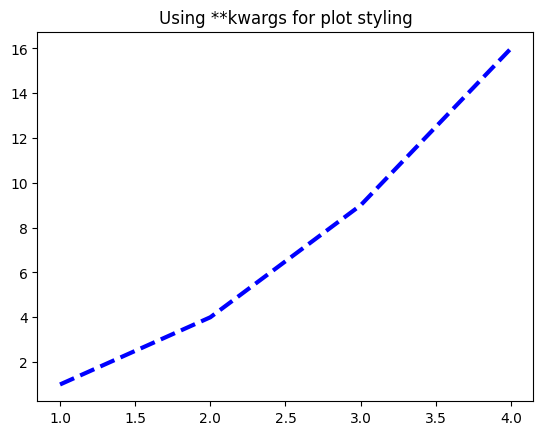

In [104]:
# Popular use case: passing shared plot styling into matplotlib (from Lecture 17!)
import matplotlib.pyplot as plt

line_style = {"color": "blue", "linestyle": "--", "linewidth": 3}
plt.plot([1, 2, 3, 4], [1, 4, 9, 16], **line_style)
plt.title("Using **kwargs for plot styling")
plt.show()

## Summary: OOP & Special Methods Cheat Sheet (Lectures 20–23)

| Feature / Method | Triggered by | Purpose |
| --- | --- | --- |
| `__init__` | `ClassName(...)` | Initialize instance attributes |
| `__str__` | `print(obj)`, `str(obj)` | Human-readable string representation |
| `__repr__` | `obj` in notebook/REPL, `repr(obj)` | Unambiguous developer representation |
| `__eq__`, `__lt__` | `==`, `<` (and `sort()`) | Value comparison between objects |
| `__add__`, `__radd__` | `obj + other`, `other + obj`, `sum()` | Operator overloading for `+` |
| `__len__` | `len(obj)` | Number of items in a container |
| `__getitem__`, `__setitem__` | `obj[i]`, slicing, `for x in obj`, `obj[i] = val` | Sequence / container indexing & assignment |
| `__iter__` | `for x in obj`, `tuple(obj)`, `*obj` | Custom iteration and unpacking |
| `@property` / `@x.setter` | `obj.x`, `obj.x = val` | Controlled attribute access and validation |